# MLP cross-check — a plain neural net on the GNN inputs, no message passing (HI-Small)

- **Question:** the GBT cross-check (§7.7) showed PNA and the Transformer above LightGBM on the same inputs. Is that message passing, or just "a neural net"? An MLP on exactly the same 93 columns — the readout's own input `[e_seed ‖ x_src ‖ x_dst]` without the learned node states — answers that.
- **Inputs:** 81 edge features (20 baseline + 61 GFP V0, as stored in the graph files) + the 6 + 6 entity one-hots of the two endpoints; one feature set only (`full`). The 81 edge columns are standardised on the train rows (std floor 1e-3); the one-hots stay 0/1.
- **Knobs:** none per run. The recipe is chosen once by random search (100 unique trials, one seed each; trial 0 = funnel 93 → 512 → 256 → 128 → 1, BatchNorm, dropout 0.2) on the **train rows**, scored on **validation**; then four seeds (42–45) are trained with it. Test is scored once per seed; every metric on train / val / test. F1 at the paper's 0.5 threshold is stored alongside for comparison only.
- **Recipe (`mlp_core.py`):** three shapes (flat, funnel, resnet), Adam at a constant LR, `BCEWithLogitsLoss(pos_weight)`, cap 60 epochs with **early stopping (patience 10) on validation PR-AUC** — every run keeps its best-validation-PR-AUC epoch, the threshold is swept on validation there, and trials are ranked by validation PR-AUC (threshold-free).
- **Everything shared** comes from `gnn_core.py` (threshold sweep, metrics, loss diagnostic, curves, summaries) and `gbt_core.py` (the 93-column matrix, predictions file) through `mlp_core.py`; this notebook only sets the budget and the paths. Logged search fits and finished seeds are skipped on rerun, so the search can span Kaggle sessions when `Outputs/MLP/search/` is committed in between.

## 0. Environment (Kaggle)

- Pinned PyTorch / PyG stack known to work on Kaggle GPU — do not change versions or order (PyG is needed to read the graph files).
- `lightgbm` is imported by `gbt_core` (the matrix builder); Kaggle ships it, the install line is a no-op then.
- Then clone (or pull) the public repo so the committed `gnn_core.py` / `gbt_core.py` / `mlp_core.py` are the ones imported.

In [1]:
!pip uninstall -y torch torchvision torchaudio torch-scatter torch-sparse pyg_lib
!pip install torch==2.8.0 torchvision torchaudio --index-url https://download.pytorch.org/whl/cu126
!pip install torch-scatter torch-sparse torch-cluster -f https://data.pyg.org/whl/torch-2.8.0+cu126.html
!pip install torch_geometric
!pip install -q lightgbm

Found existing installation: torch 2.11.0+cu128
Uninstalling torch-2.11.0+cu128:
  Successfully uninstalled torch-2.11.0+cu128
Found existing installation: torchvision 0.26.0+cu128
Uninstalling torchvision-0.26.0+cu128:
  Successfully uninstalled torchvision-0.26.0+cu128
Found existing installation: torchaudio 2.11.0+cu128
Uninstalling torchaudio-2.11.0+cu128:
  Successfully uninstalled torchaudio-2.11.0+cu128
Looking in indexes: https://download.pytorch.org/whl/cu126
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.7/23.7 MB 149.4 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 897.7/897.7 kB 11.5 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 250.5 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 706.8/706.8 MB 238.7 MB/s  0:00:02
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 393.1/393.1 MB 255.0 MB/s  0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 200.2/200.2 MB 214.7 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56

In [2]:
import os
import sys

REPO_URL = 'https://github.com/sandrokhizanishvili/gnn_for_fraudulent_patterns.git'
REPO_DIR = '/kaggle/working/gnn_for_fraudulent_patterns'
if os.path.isdir(REPO_DIR):
    !git -C {REPO_DIR} pull
else:
    !git clone {REPO_URL} {REPO_DIR}
!git -C {REPO_DIR} log -1 --oneline
sys.path.append(REPO_DIR)

Cloning into '/kaggle/working/gnn_for_fraudulent_patterns'...
remote: Enumerating objects: 992, done.
remote: Counting objects: 100% (43/43), done.
remote: Compressing objects: 100% (35/35), done.
remote: Total 992 (delta 8), reused 37 (delta 8), pack-reused 949 (from 1)
Receiving objects: 100% (992/992), 47.30 MiB | 36.72 MiB/s, done.
Resolving deltas: 100% (308/308), done.
68cefd2 (HEAD -> main, origin/main, origin/HEAD) MLP cross-check: mlp_core.py + MLP_fixed_features.ipynb (Kaggle), plan in EXPERIMENTS/Progress_Report/CLAUDE/README


## 1. Configuration

- The only settings cell: the search budget, the seeds and the paths.
- `OUT_ROOT` sits inside the repo clone, mirroring `Outputs/MLP/`: committed search fits (`search/trials.csv`) and finished seeds are skipped on the next session.

In [3]:
import json

import gnn_core as core
import gbt_core
import mlp_core

N_TRIALS     = mlp_core.N_TRIALS       # 100 unique trials; trial 0 = the default knobs (funnel 93 -> 512 -> 256 -> 128 -> 1)
SEARCH_SEEDS = mlp_core.SEARCH_SEEDS   # (42,): one seed per trial; the trial score is its best val PR-AUC
SEEDS        = mlp_core.SEEDS          # (42, 43, 44, 45) final seeds; 42 is the run compared with the GNN runs

DATA_DIR = '/kaggle/input/datasets/sandrokhizanishvili/hi-small-gnn'
OUT_ROOT = f'{REPO_DIR}/Outputs/MLP'
os.makedirs(f'{OUT_ROOT}/search', exist_ok=True)
print(f'torch {core.torch.__version__} | device {core.device} | cap {mlp_core.EPOCHS} epochs, patience {mlp_core.PATIENCE} '
      f'on validation PR-AUC | out {OUT_ROOT}')
print('trial 0:', json.dumps(mlp_core.DEFAULT_KNOBS))
print('search space:', json.dumps(mlp_core.SEARCH_SPACE))

torch 2.8.0+cu126 | device cuda | cap 60 epochs, patience 10 on validation PR-AUC | out /kaggle/working/gnn_for_fraudulent_patterns/Outputs/MLP
trial 0: {"hidden": 512, "depth": 3, "shape": "funnel", "norm": "batch", "dropout": 0.2, "lr": 0.001, "weight_decay": 0.0001, "pos_weight": 8.0, "batch_size": 8192}
search space: {"hidden": [128, 256, 512, 1024], "depth": [2, 3, 4, 5], "shape": ["flat", "funnel", "resnet"], "norm": ["none", "batch"], "dropout": [0.1, 0.2, 0.3, 0.5], "lr": [0.0003, 0.001, 0.003], "weight_decay": [0.0, 1e-05, 0.0001, 0.001], "pos_weight": [4.0, 8.0, 16.0], "batch_size": [2048, 8192]}


## 2. Load data

- One row per edge from the graph files: `edge_attr` (81) ‖ `x[src]` (6) ‖ `x[dst]` (6); labels of the train / val windows from their own snapshots (the GBT matrix, asserted against `Progress_Report.md` §4).
- The 81 edge columns are standardised with the train-row mean / std; the 12 one-hots stay 0/1. The whole matrix then goes to the GPU once.

In [4]:
data = gbt_core.load_gbt_data(DATA_DIR)
scaler = mlp_core.standardise(data)
X, y = mlp_core.to_tensors(data)

GBT matrix (5077237, 93) float32 (1.76 GB): 81 edge + 6 src + 6 dst columns
train rows         0 – 3,046,341  n=3,046,342  laundering=2,297 (0.0754%)
val   rows 3,046,342 – 4,061,788  n=1,015,447  laundering=1,082 (0.1066%)
test  rows 4,061,789 – 5,077,236  n=1,015,448  laundering=1,143 (0.1126%)
scaled 81 edge columns on 3,046,342 train rows (std floor 0.001, 5 columns at the floor); largest |value| after scaling 1000.0; 12 one-hot columns untouched
X (5077237, 93) float32 (1.76 GB) and y on cuda


## 3. Model

- `mlp_core.MLP`: flat / funnel = `[Linear → BatchNorm → ReLU → Dropout]` per hidden width, then `Linear → 1`; resnet = `Linear → hidden`, residual blocks `z + Linear(Dropout(ReLU(BatchNorm(Linear(z)))))`, then `Linear → 1`.
- Trial 0 below; the search draws the shape, widths, depth, normalisation, dropout, learning rate, weight decay, `pos_weight` and batch size.

In [5]:
model = mlp_core.MLP(X.shape[1], mlp_core.DEFAULT_KNOBS)
print(model)
print(f"trial 0: {mlp_core.DEFAULT_KNOBS['shape']} {mlp_core.widths_text(X.shape[1], model.widths, mlp_core.DEFAULT_KNOBS['shape'])} "
      f"| params {core.count_params(model):,}")
del model

MLP(
  (net): Sequential(
    (0): Linear(in_features=93, out_features=512, bias=True)
    (1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=512, out_features=256, bias=True)
    (5): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=256, out_features=128, bias=True)
    (9): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.2, inplace=False)
    (12): Linear(in_features=128, out_features=1, bias=True)
  )
)
trial 0: funnel 93 -> 512 -> 256 -> 128 -> 1 | params 214,273


## 4. Hyperparameter search — random search on the train rows, early stopping on validation PR-AUC

- Every trial is trained once (seed 42); the fit stops after 10 epochs without a better validation PR-AUC and keeps its best epoch; that epoch's validation PR-AUC ranks the trial (F1 and threshold recorded).
- `search/trials.csv` gets one line per (trial, seed) as soon as it finishes (shape, widths, params, epochs, seconds per epoch); `search/best_params.json` holds the winner.
- Test is not touched here.

In [6]:
best_knobs, trials = mlp_core.random_search(data, X, y, f'{OUT_ROOT}/search', N_TRIALS, SEARCH_SEEDS)
scores = trials.groupby('trial').agg(shape=('shape', 'first'), widths=('widths', 'first'), params=('params', 'first'),
                                     val_pr_auc=('val_pr_auc', 'mean'), val_f1=('val_f1', 'mean'),
                                     best_epoch=('best_epoch', 'mean'), sec_per_epoch=('sec_per_epoch', 'mean'), n_seeds=('seed', 'count'))
scores[scores['n_seeds'] == len(SEARCH_SEEDS)].sort_values('val_pr_auc', ascending=False).head(10).round(4)

100 unique trials (trial 0 = the default knobs, 0 duplicate draws redrawn)
random search: 100 trials x seeds (42,) | ranked by val_pr_auc | cap 60 epochs, patience 10 | 0 fits already logged
--- trial 0 seed 42
funnel 93 -> 512 -> 256 -> 128 -> 1 | params 214,273 | seed 42 | norm=batch dropout=0.2 lr=0.001 weight_decay=0.0001 pos_weight=8.0 batch_size=8192
epoch   1 | loss 0.0207 / 0.0251 | F1 0.3769 / 0.4254 @ 0.579 | PR-AUC 0.1881 / 0.2362 | 4.5s   (train / val)  * new best
epoch   2 | loss 0.0170 / 0.0214 | F1 0.4044 / 0.4578 @ 0.647 | PR-AUC 0.3344 / 0.3828 | 4.1s   (train / val)  * new best
epoch   3 | loss 0.0165 / 0.0210 | F1 0.4203 / 0.4682 @ 0.601 | PR-AUC 0.3481 / 0.3746 | 4.0s   (train / val)
epoch   4 | loss 0.0162 / 0.0206 | F1 0.4204 / 0.4747 @ 0.603 | PR-AUC 0.3471 / 0.3935 | 4.1s   (train / val)  * new best
epoch   5 | loss 0.0163 / 0.0211 | F1 0.4229 / 0.4831 @ 0.595 | PR-AUC 0.3365 / 0.3741 | 4.1s   (train / val)
epoch   6 | loss 0.0156 / 0.0197 | F1 0.4356 / 0.4945 @

,shape,widths,params,val_pr_auc,val_f1,best_epoch,sec_per_epoch,n_seeds
trial,,,,,,,,
28,flat,93 -> 512 -> 512 -> 512 -> 512 -> 1,840705,0.4731,0.5400,12.0,11.1016,1
22,funnel,93 -> 256 -> 128 -> 64 -> 32 -> 1,68289,0.4657,0.5388,23.0,6.5597,1
41,flat,93 -> 1024 -> 1024 -> 1024 -> 1024 -> 1024 -> 1,4305921,0.4635,0.5404,25.0,36.9305,1
76,flat,93 -> 512 -> 512 -> 512 -> 512 -> 1,840705,0.4584,0.5344,34.0,10.2223,1
43,flat,93 -> 256 -> 256 -> 256 -> 1,157441,0.4570,0.5340,41.0,6.1038,1
69,resnet,93 -> 1024 (3 residual blocks) -> 1,6401025,0.4568,0.5283,19.0,57.3748,1
15,funnel,93 -> 128 -> 64 -> 32 -> 16 -> 16 -> 1,23697,0.4566,0.5246,50.0,3.1095,1
19,funnel,93 -> 256 -> 128 -> 64 -> 1,66177,0.4555,0.5362,27.0,5.9005,1
51,funnel,93 -> 1024 -> 512 -> 256 -> 128 -> 64 -> 1,793601,0.4539,0.5416,18.0,8.3977,1


## 5. Final runs — four seeds with the chosen knobs

- One call per seed: train rows → early stopping on validation PR-AUC → the best epoch kept, threshold swept there → all splits scored → `results.json`, `history.csv`, `curves.png`, `best.pt`, `predictions.csv` under `OUT_ROOT/<run>/`.
- `history.csv` has one row per epoch; `curves.png` marks the kept epoch.

=== mlp_readout-full_seed-42 ===
flat 93 -> 512 -> 512 -> 512 -> 512 -> 1 | params 840,705 | seed 42 | norm=batch dropout=0.2 lr=0.003 weight_decay=0.0 pos_weight=4.0 batch_size=2048
epoch   1 | loss 0.0179 / 0.0227 | F1 0.4221 / 0.4914 @ 0.328 | PR-AUC 0.3405 / 0.4114 | 11.1s   (train / val)  * new best
epoch   2 | loss 0.0159 / 0.0214 | F1 0.4148 / 0.4948 @ 0.358 | PR-AUC 0.3435 / 0.4011 | 11.1s   (train / val)
epoch   3 | loss 0.0172 / 0.0226 | F1 0.4455 / 0.4933 @ 0.192 | PR-AUC 0.3719 / 0.4186 | 11.2s   (train / val)  * new best
epoch   4 | loss 0.0155 / 0.0203 | F1 0.4459 / 0.5047 @ 0.581 | PR-AUC 0.3784 / 0.4207 | 11.1s   (train / val)  * new best
epoch   5 | loss 0.0159 / 0.0207 | F1 0.4470 / 0.5014 @ 0.555 | PR-AUC 0.3805 / 0.4300 | 11.0s   (train / val)  * new best
epoch   6 | loss 0.0163 / 0.0217 | F1 0.4778 / 0.5264 @ 0.456 | PR-AUC 0.4031 / 0.4432 | 11.0s   (train / val)  * new best
epoch   7 | loss 0.0155 / 0.0216 | F1 0.4821 / 0.5271 @ 0.508 | PR-AUC 0.4092 / 0.4482 | 11

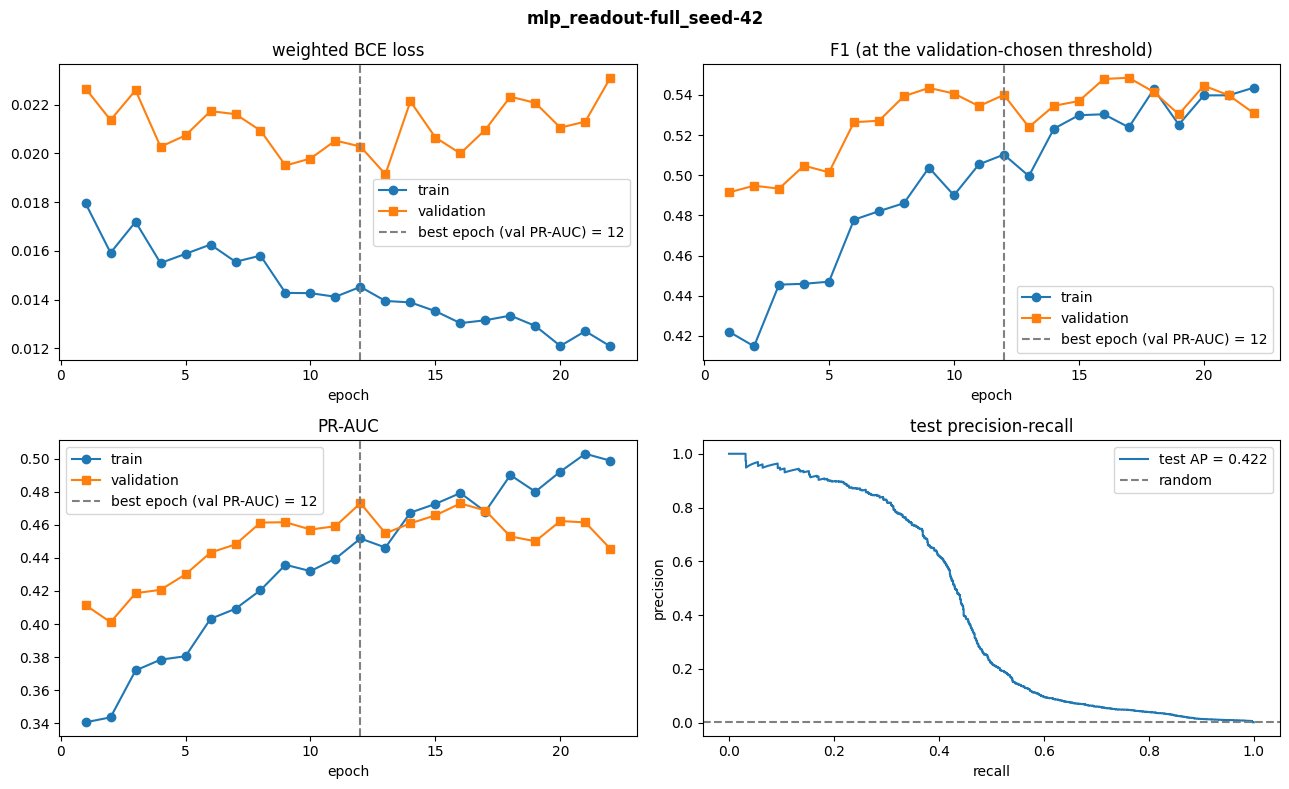

=== mlp_readout-full_seed-43 ===
flat 93 -> 512 -> 512 -> 512 -> 512 -> 1 | params 840,705 | seed 43 | norm=batch dropout=0.2 lr=0.003 weight_decay=0.0 pos_weight=4.0 batch_size=2048
epoch   1 | loss 0.0179 / 0.0230 | F1 0.3922 / 0.4616 @ 0.706 | PR-AUC 0.3167 / 0.3818 | 11.0s   (train / val)  * new best
epoch   2 | loss 0.0166 / 0.0218 | F1 0.4300 / 0.4966 @ 0.337 | PR-AUC 0.3561 / 0.4169 | 11.5s   (train / val)  * new best
epoch   3 | loss 0.0165 / 0.0222 | F1 0.4325 / 0.5046 @ 0.214 | PR-AUC 0.3500 / 0.4118 | 11.8s   (train / val)
epoch   4 | loss 0.0181 / 0.0250 | F1 0.4064 / 0.4502 @ 0.399 | PR-AUC 0.2408 / 0.2799 | 11.2s   (train / val)
epoch   5 | loss 0.0152 / 0.0206 | F1 0.4608 / 0.5141 @ 0.403 | PR-AUC 0.3964 / 0.4360 | 11.0s   (train / val)  * new best
epoch   6 | loss 0.0153 / 0.0207 | F1 0.4698 / 0.5084 @ 0.499 | PR-AUC 0.3977 / 0.4273 | 10.9s   (train / val)
epoch   7 | loss 0.0166 / 0.0230 | F1 0.4703 / 0.5271 @ 0.460 | PR-AUC 0.4127 / 0.4427 | 10.9s   (train / val)  * n

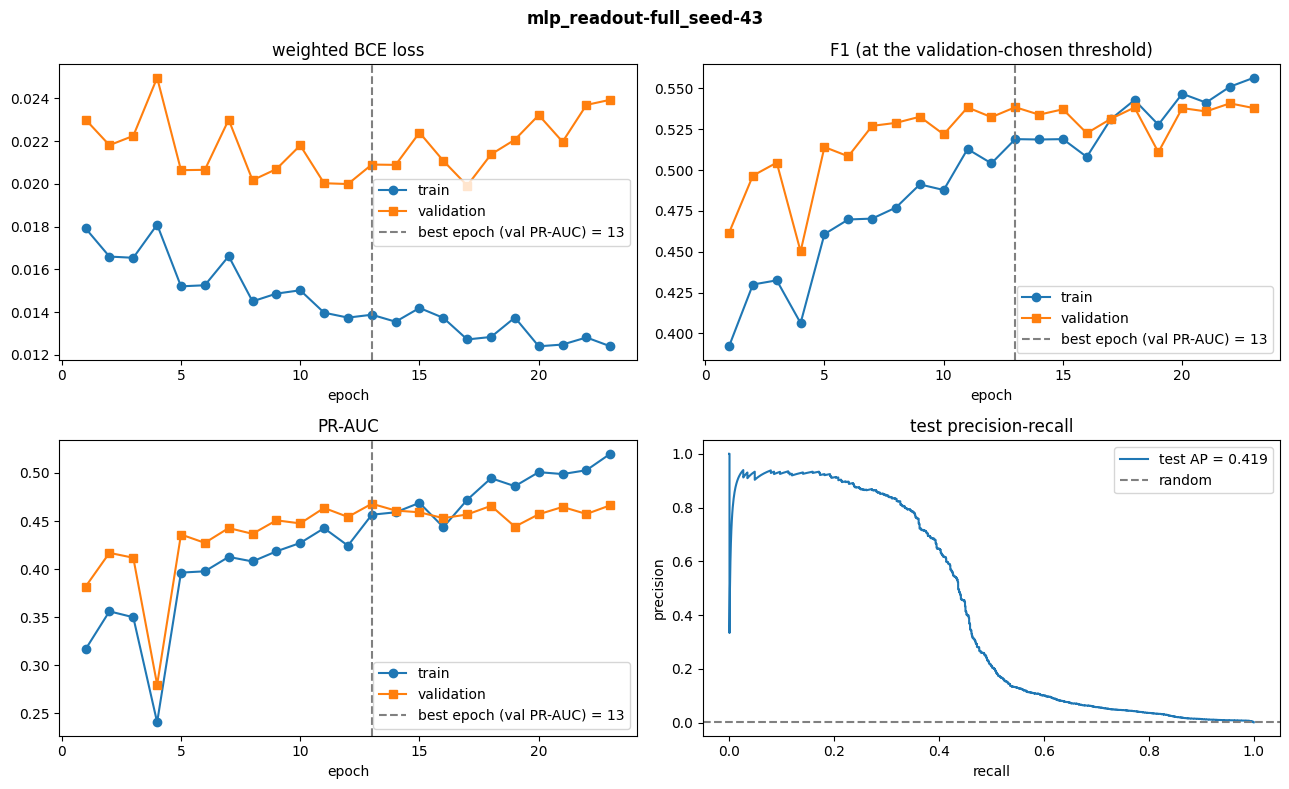

=== mlp_readout-full_seed-44 ===
flat 93 -> 512 -> 512 -> 512 -> 512 -> 1 | params 840,705 | seed 44 | norm=batch dropout=0.2 lr=0.003 weight_decay=0.0 pos_weight=4.0 batch_size=2048
epoch   1 | loss 0.0174 / 0.0217 | F1 0.4046 / 0.4799 @ 0.650 | PR-AUC 0.3287 / 0.3947 | 11.1s   (train / val)  * new best
epoch   2 | loss 0.0171 / 0.0229 | F1 0.4305 / 0.4973 @ 0.447 | PR-AUC 0.3523 / 0.4034 | 11.4s   (train / val)  * new best
epoch   3 | loss 0.0163 / 0.0206 | F1 0.4274 / 0.4895 @ 0.728 | PR-AUC 0.3566 / 0.4186 | 11.8s   (train / val)  * new best
epoch   4 | loss 0.0167 / 0.0217 | F1 0.4435 / 0.4943 @ 0.623 | PR-AUC 0.3709 / 0.4235 | 11.3s   (train / val)  * new best
epoch   5 | loss 0.0166 / 0.0218 | F1 0.4289 / 0.5017 @ 0.444 | PR-AUC 0.3523 / 0.4019 | 11.0s   (train / val)
epoch   6 | loss 0.0162 / 0.0218 | F1 0.4654 / 0.5282 @ 0.517 | PR-AUC 0.3978 / 0.4339 | 10.9s   (train / val)  * new best
epoch   7 | loss 0.0145 / 0.0195 | F1 0.4723 / 0.5188 @ 0.382 | PR-AUC 0.4034 / 0.4397 | 10

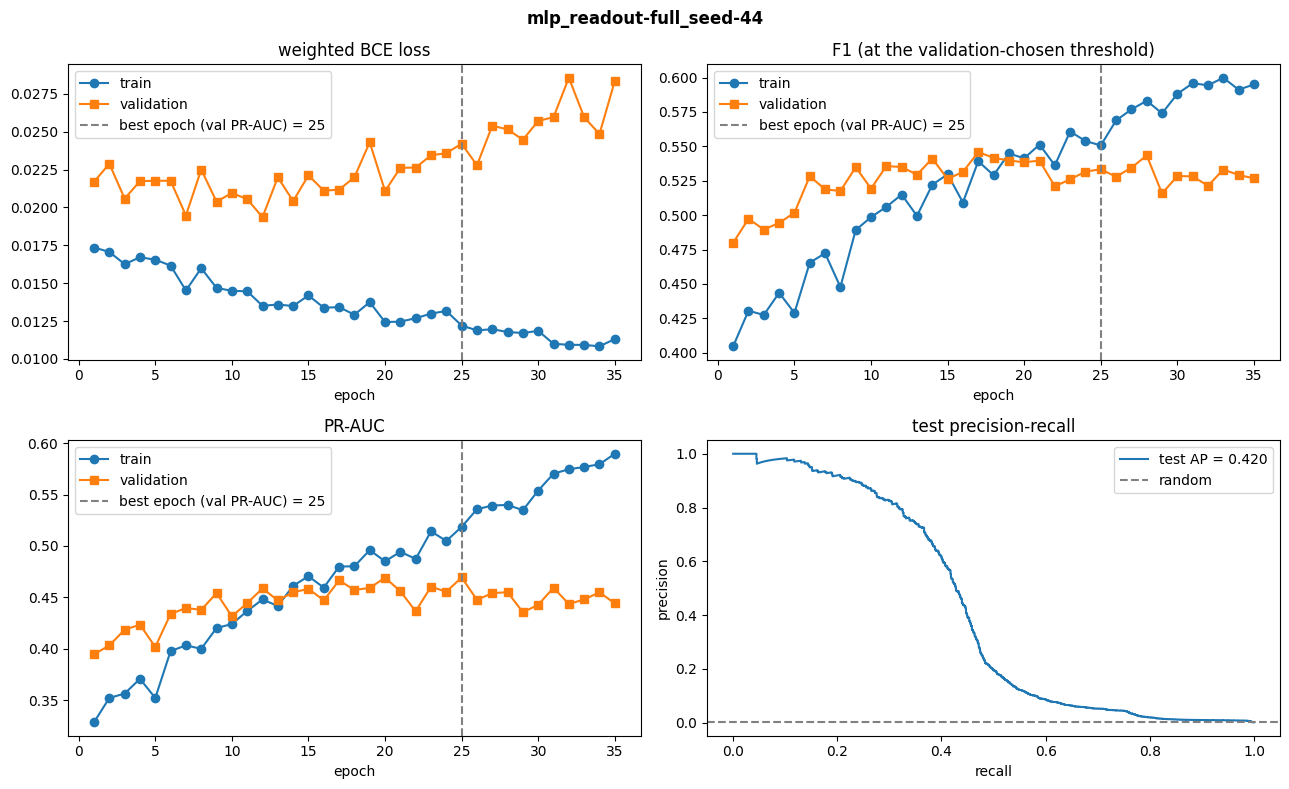

=== mlp_readout-full_seed-45 ===
flat 93 -> 512 -> 512 -> 512 -> 512 -> 1 | params 840,705 | seed 45 | norm=batch dropout=0.2 lr=0.003 weight_decay=0.0 pos_weight=4.0 batch_size=2048
epoch   1 | loss 0.0167 / 0.0219 | F1 0.4035 / 0.4503 @ 0.722 | PR-AUC 0.3298 / 0.3542 | 11.0s   (train / val)  * new best
epoch   2 | loss 0.0163 / 0.0214 | F1 0.4253 / 0.4719 @ 0.328 | PR-AUC 0.3471 / 0.3780 | 11.4s   (train / val)  * new best
epoch   3 | loss 0.0153 / 0.0196 | F1 0.4367 / 0.4990 @ 0.521 | PR-AUC 0.3485 / 0.4075 | 11.8s   (train / val)  * new best
epoch   4 | loss 0.0152 / 0.0197 | F1 0.4628 / 0.5248 @ 0.486 | PR-AUC 0.3804 / 0.4353 | 11.2s   (train / val)  * new best
epoch   5 | loss 0.0149 / 0.0189 | F1 0.4673 / 0.5121 @ 0.616 | PR-AUC 0.3875 / 0.4340 | 11.0s   (train / val)
epoch   6 | loss 0.0150 / 0.0207 | F1 0.4724 / 0.5051 @ 0.560 | PR-AUC 0.3936 / 0.4189 | 10.9s   (train / val)
epoch   7 | loss 0.0154 / 0.0214 | F1 0.4797 / 0.5236 @ 0.452 | PR-AUC 0.4099 / 0.4409 | 10.9s   (train

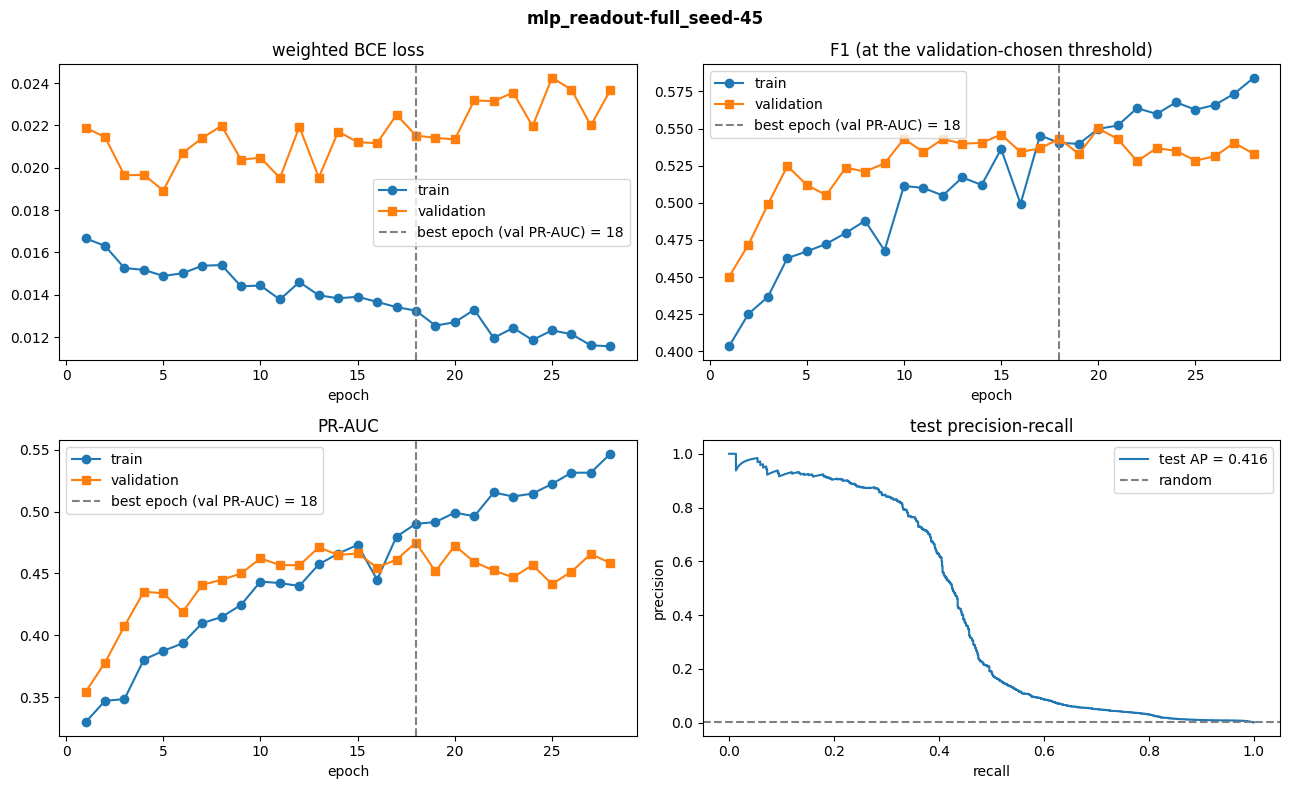

batch complete


In [7]:
rows = []
for seed in SEEDS:
    print('=' * 90)
    rows.append(mlp_core.train_final(best_knobs, data, X, y, seed, OUT_ROOT))
print('=' * 90)
print('batch complete')

## 6. Comparison across the seeds

- `batch_summary_mlp.csv` holds every `<split>_<metric>` column plus `threshold`, `best_epoch`, `params`, `invariant_params` (0 by convention).
- `seed_summary_mlp.csv`: mean ± std over the four seeds. Only test F1 and PR-AUC are fair scores here — validation picked the hyperparameters, the kept epoch and the threshold.

In [8]:
summary = core.summarize_batch(rows, OUT_ROOT, 'batch_summary_mlp.csv')
display(summary[core.DISPLAY_COLS].round(4))
seeds = mlp_core.seed_summary(rows, OUT_ROOT)
seeds[['n_seeds', 'val_f1_mean', 'val_f1_std', 'test_f1_mean', 'test_f1_std',
       'test_pr_auc_mean', 'test_pr_auc_std', 'best_epoch_mean']].round(4)

4 runs -> /kaggle/working/gnn_for_fraudulent_patterns/Outputs/MLP/batch_summary_mlp.csv | invariant_params = 0 in the first row (identical in every row)


,run,best_epoch,threshold,val_f1,test_f1,test_precision,test_recall,test_pr_auc,test_precision_at_5pct,test_recall_at_5pct,params,invariant_params
0,mlp_readout-full_seed-42,12,0.3813,0.5400,0.4870,0.6008,0.4094,0.4221,0.0196,0.8723,840705,0
1,mlp_readout-full_seed-43,13,0.5367,0.5385,0.4938,0.6858,0.3858,0.4191,0.0194,0.8609,840705,0
2,mlp_readout-full_seed-44,25,0.6162,0.5333,0.4809,0.5879,0.4068,0.4199,0.0182,0.8066,840705,0
3,mlp_readout-full_seed-45,18,0.6402,0.5432,0.4928,0.7143,0.3762,0.4155,0.0186,0.8259,840705,0


4 seeds -> /kaggle/working/gnn_for_fraudulent_patterns/Outputs/MLP/seed_summary_mlp.csv


,n_seeds,val_f1_mean,val_f1_std,test_f1_mean,test_f1_std,test_pr_auc_mean,test_pr_auc_std,best_epoch_mean
0,4,0.5388,0.0041,0.4886,0.006,0.4192,0.0027,17.0


## 7. Download

- Zip `OUT_ROOT`; extract into `Outputs/MLP/` in the repo and commit the small result files (`best.pt` and `predictions.csv` stay out of git). Commit `search/trials.csv` after a session that did not finish the search — the next session resumes from it.

In [9]:
import shutil
shutil.make_archive('/kaggle/working/Outputs_MLP', 'zip', OUT_ROOT)

'/kaggle/working/Outputs_MLP.zip'